# Graph Construction & Community Detection



In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import adjusted_rand_score as ARI
from sklearn.metrics.pairwise import cosine_similarity
warnings.filterwarnings("ignore")

SEED = 42                   
SEEDS = list(range(10))      # seed Louvain untuk uji stabilitas; partisi yang dipakai = seed dengan modularity tertinggi

K_SEMANTIC = 6
K_SPATIAL = 6
WEIGHT_SEMANTIC = 1.0
WEIGHT_SPATIAL = 1.0
WEIGHT_TEMPORAL = 1.0        
NORMALIZE_LAYERS = True     

# Grid desain utama (spasial berbobot semantik)
SCOPE_GRID = ["same_year", "spatio_temporal", "spatio_temporal_consecutive", "same_year+temporal"]
K_GEO_GRID = [5, 8, 12]      # jumlah kelurahan tetangga terdekat yang boleh terhubung
M_GRID = [6, 10]             # tiap node MEMILIH M tetangga terkuat; setelah simetrisasi derajat akhir bisa > M

# pemilihan konfigurasi
MIN_ARI = 0.75               # stabilitas antar seed
MIN_COMM_SIZE = 10           # tanpa komunitas kecil/singleton
MAX_SPAT_RATIO = 0.60        # komunitas harus jelas lebih kompak secara geografis daripada acak
OVERRIDE_CONFIG = None       # contoh: {"scope": "spatio_temporal", "k_geo": 8, "m": 6}

LOW_VOLUME_THRESHOLD = 10
EXPECTED_NODES = 459         # 153 kelurahan x 3 tahun; ubah hanya jika dataset final memang berubah
EXPECTED_KELURAHAN = 153

BASE_DIR = Path.cwd()
OUTPUT_DIR = BASE_DIR / "semantic_output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
NODE_PATH = OUTPUT_DIR / "node_table_kelurahan_tahun.csv"
EMBED_PATH = OUTPUT_DIR / "node_embeddings_kelurahan_tahun.npy"

def find_file(patterns, search_dirs):
    for d in search_dirs:
        for p in patterns:
            hits = sorted(Path(d).glob(p))
            if hits:
                return hits[0]
    return None

DATA_PATH_OVERRIDE = None   
DATA_PATH = Path(DATA_PATH_OVERRIDE) if DATA_PATH_OVERRIDE else find_file(
    ["data_cleaned.csv"], [BASE_DIR, BASE_DIR / "cleaning_output", BASE_DIR.parent / "cleaning_output",
                           Path("/content"), Path("/content/drive/MyDrive")])

print("Folder kerja :", BASE_DIR)
print("Tabel node   :", NODE_PATH, "| exists:", NODE_PATH.exists())
print("Embedding    :", EMBED_PATH, "| exists:", EMBED_PATH.exists())
print("data_cleaned :", DATA_PATH, "(validasi topik", "aktif)" if DATA_PATH else "NONAKTIF: topic_gain tidak dihitung)")
if DATA_PATH is not None:
    import time as _t; print("   terakhir diubah:", _t.strftime("%Y-%m-%d %H:%M", _t.localtime(Path(DATA_PATH).stat().st_mtime)))
assert NODE_PATH.exists(), "node_table_kelurahan_tahun.csv tidak ditemukan. Sesuaikan BASE_DIR ke folder proyek Notebook 03."
assert EMBED_PATH.exists(), "node_embeddings_kelurahan_tahun.npy tidak ditemukan. Jalankan Notebook 03 terlebih dahulu."

Folder kerja : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A
Tabel node   : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\semantic_output\node_table_kelurahan_tahun.csv | exists: True
Embedding    : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\semantic_output\node_embeddings_kelurahan_tahun.npy | exists: True
data_cleaned : c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\cleaning_output\data_cleaned.csv (validasi topik aktif)
   terakhir diubah: 2026-10-29 09:02


## 1. Muat data, validasi alignment, jarak, dan profil topik (untuk validasi)

In [2]:
nodes = pd.read_csv(NODE_PATH, low_memory=False)
X = np.load(EMBED_PATH)

required = ["node_id", "lokasi_key", "kelurahan", "kecamatan", "tahun", "n_pengaduan", "lat_kelurahan", "lon_kelurahan"]
missing = [c for c in required if c not in nodes.columns]
assert not missing, f"Kolom wajib tidak ada: {missing}"

nodes["node_id"] = pd.to_numeric(nodes["node_id"], errors="raise").astype(int)
nodes["tahun"] = pd.to_numeric(nodes["tahun"], errors="raise").astype(int)
nodes = nodes.sort_values("node_id").reset_index(drop=True)
nodes["lokasi_key"] = nodes["lokasi_key"].astype(str)

assert nodes["node_id"].is_unique, "node_id harus unik."
assert np.array_equal(nodes["node_id"].to_numpy(), np.arange(len(nodes))), "node_id harus berurutan 0..N-1."
assert X.ndim == 2 and X.shape[0] == len(nodes), f"Shape embedding {X.shape} tidak cocok dengan tabel {nodes.shape}."
assert np.isfinite(X).all(), "Embedding mengandung NaN/inf."
assert nodes[["lat_kelurahan", "lon_kelurahan"]].notna().all().all(), "Ada koordinat yang kosong."
assert set(nodes["tahun"].unique()) == {2023, 2024, 2025}, "Tahun yang ditemukan tidak sesuai ekspektasi."
assert np.allclose(np.linalg.norm(X, axis=1), 1.0, atol=1e-4), "Embedding node seharusnya L2-normalized."

N = len(nodes)
assert N == EXPECTED_NODES and nodes["lokasi_key"].nunique() == EXPECTED_KELURAHAN, (
    f"Jumlah node/kelurahan ({N}/{nodes['lokasi_key'].nunique()}) tidak sesuai ekspektasi ({EXPECTED_NODES}/{EXPECTED_KELURAHAN}).")
assert not nodes.duplicated(["lokasi_key", "tahun"]).any(), "Ada pasangan lokasi_key x tahun yang duplikat."
assert (nodes.groupby("lokasi_key").size() == 3).all(), "Setiap kelurahan harus memiliki tepat tiga node (satu per tahun)."
assert (nodes.groupby("lokasi_key")[["lat_kelurahan", "lon_kelurahan"]].nunique() <= 1).all().all(), "Koordinat kelurahan tidak konsisten antar tahun."
lk = nodes["lokasi_key"].to_numpy()
yr = nodes["tahun"].to_numpy()
same_yr = yr[:, None] == yr[None, :]
iu = np.triu_indices(N, 1)

SIM = cosine_similarity(X)              
gap = SIM[(lk[:, None] == lk[None, :]) & ~same_yr].mean() - SIM[iu].mean()
print(f"Gap kelurahan sama beda tahun vs acak: {gap:.4f}")
assert gap > 0.2, "Urutan node tidak selaras dengan embedding."

display(pd.DataFrame([{"nodes": N, "embedding_dim": X.shape[1], "kelurahan": nodes["lokasi_key"].nunique(),
                       "total_pengaduan": int(nodes["n_pengaduan"].sum()),
                       "low_volume_nodes": int((nodes["n_pengaduan"] < LOW_VOLUME_THRESHOLD).sum())}]))

# jarak haversine (km)
EARTH_RADIUS_KM = 6371.0088
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2.0) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

coords = nodes[["lat_kelurahan", "lon_kelurahan"]].to_numpy(dtype=float)
D = haversine_km(coords[:, 0][:, None], coords[:, 1][:, None], coords[:, 0][None, :], coords[:, 1][None, :])   # node x node
ukel = sorted(set(lk)); kidx = {k: i for i, k in enumerate(ukel)}
ki = np.array([kidx[k] for k in lk])                        # node -> indeks kelurahan
first_idx = [int(np.flatnonzero(lk == k)[0]) for k in ukel]
Dk = D[np.ix_(first_idx, first_idx)]                        # kelurahan x kelurahan (153 x 153)

# profil topik per node (centered) HANYA untuk evaluasi; tidak membentuk graf
ST = None
if DATA_PATH is not None:
    dfc = pd.read_csv(DATA_PATH, usecols=["lokasi_key", "tahun", "kelompok_topik"], low_memory=False)
    dfc["lokasi_key"] = dfc["lokasi_key"].astype(str)
    tp = (dfc.groupby(["lokasi_key", "tahun"])["kelompok_topik"].value_counts(normalize=True).unstack(fill_value=0))
    assert len(dfc) == int(nodes["n_pengaduan"].sum()), (
        f"data_cleaned.csv ({len(dfc)} baris) tidak konsisten dengan tabel node ({int(nodes['n_pengaduan'].sum())} pengaduan): "
        "kemungkinan salinan lama; set DATA_PATH_OVERRIDE.")
    tp = tp.loc[list(zip(lk, yr))].to_numpy()
    tpc = tp - tp.mean(0); _nrm = np.linalg.norm(tpc, axis=1, keepdims=True)
    assert (_nrm > 0).all(), "Ada node dengan profil topik identik dengan rata-rata (norma nol setelah centering)."
    tpc = tpc / _nrm
    ST = tpc @ tpc.T
    print("Profil topik siap:", tp.shape)

Gap kelurahan sama beda tahun vs acak: 0.3088


,nodes,embedding_dim,kelurahan,total_pengaduan,low_volume_nodes
0,459,768,153,33880,6


Profil topik siap: (459, 16)


## A. Layer pembanding (desain awal)

Tiga layer dibangun seperti desain awal: semantik **global** (top-k dari seluruh node), spasial (top-k tetangga terdekat pada tahun yang sama), dan temporal (kelurahan sama pada tahun berurutan).

In [3]:
S = SIM.copy()
np.fill_diagonal(S, -np.inf)
semantic_edges = {}
for i in range(N):
    nbrs = np.argsort(-S[i], kind="stable")[:min(K_SEMANTIC, N - 1)]
    for j in nbrs:
        j = int(j); a, b = sorted((int(i), j)); sim = float(S[i, j])
        if (a, b) not in semantic_edges:
            semantic_edges[(a, b)] = {"similarity": sim, "weight_semantic": max(sim, 0.0)}
print("Jumlah edge semantik (global):", len(semantic_edges))

spatial_edges = {}
for year in sorted(nodes["tahun"].unique()):
    ids = np.flatnonzero(yr == year)
    for i in ids:
        cand = ids[ids != i]
        dists = D[i, cand]
        for pos in np.argsort(dists, kind="stable")[:min(K_SPATIAL, len(cand))]:
            j = int(cand[pos]); d = float(dists[pos]); key = tuple(sorted((int(i), j)))
            if key not in spatial_edges or d < spatial_edges[key]["distance_km"]:
                spatial_edges[key] = {"distance_km": d}
positive_distances = [v["distance_km"] for v in spatial_edges.values() if v["distance_km"] > 0]
distance_scale = float(np.median(positive_distances)) if positive_distances else 1.0
for v in spatial_edges.values():
    v["weight_spatial"] = float(np.exp(-v["distance_km"] / max(distance_scale, 1e-9)))
print("Jumlah edge spasial:", len(spatial_edges), "| skala jarak median (km):", round(distance_scale, 4))

temporal_edges = {}
lookup = {(str(r.lokasi_key), int(r.tahun)): int(r.node_id) for r in nodes.itertuples(index=False)}
for key in nodes["lokasi_key"].unique():
    for year in (2023, 2024):
        left, right = lookup.get((key, year)), lookup.get((key, year + 1))
        if left is not None and right is not None:
            temporal_edges[tuple(sorted((left, right)))] = {"weight_temporal": 1.0}
print("Jumlah edge temporal:", len(temporal_edges))
assert len(temporal_edges) == nodes["lokasi_key"].nunique() * 2, "Setiap kelurahan harus memiliki tiga tahun."

Jumlah edge semantik (global): 2326
Jumlah edge spasial: 1641 | skala jarak median (km): 1.5481
Jumlah edge temporal: 306


In [4]:
all_pairs = set(semantic_edges) | set(spatial_edges) | set(temporal_edges)
rows = []
for a, b in sorted(all_pairs):
    se, sp, te = semantic_edges.get((a, b), {}), spatial_edges.get((a, b), {}), temporal_edges.get((a, b), {})
    rows.append({"source": a, "target": b,
                 "similarity_semantic": se.get("similarity", np.nan), "distance_km": sp.get("distance_km", np.nan),
                 "weight_semantic": float(se.get("weight_semantic", 0.0)),
                 "weight_spatial": float(sp.get("weight_spatial", 0.0)),
                 "weight_temporal": float(te.get("weight_temporal", 0.0)),
                 "has_semantic": int((a, b) in semantic_edges), "has_spatial": int((a, b) in spatial_edges),
                 "has_temporal": int((a, b) in temporal_edges)})
edges = pd.DataFrame(rows)

def scale_to_unit_mean(s):
    pos = s[s > 0]
    return s / pos.mean() if len(pos) else s

for c in ["semantic", "spatial", "temporal"]:
    edges[f"weight_{c}_norm"] = scale_to_unit_mean(edges[f"weight_{c}"])
edges["weight_combined_raw"] = (WEIGHT_SEMANTIC * edges["weight_semantic"] + WEIGHT_SPATIAL * edges["weight_spatial"]
                                + WEIGHT_TEMPORAL * edges["weight_temporal"])
edges["weight_combined_norm"] = (WEIGHT_SEMANTIC * edges["weight_semantic_norm"] + WEIGHT_SPATIAL * edges["weight_spatial_norm"]
                                 + WEIGHT_TEMPORAL * edges["weight_temporal_norm"])
edges["weight_combined"] = edges["weight_combined_norm"] if NORMALIZE_LAYERS else edges["weight_combined_raw"]
assert (edges["weight_combined"] >= 0).all()

print("Skala bobot sisi (rata-rata | maks), sebelum normalisasi:")
for c in ["weight_semantic", "weight_spatial", "weight_temporal"]:
    v = edges[c][edges[c] > 0]; print(f"  {c:16s} n={len(v):5d} mean={v.mean():.3f} max={v.max():.3f}")

G = nx.Graph()
for r in nodes.itertuples(index=False):
    G.add_node(int(r.node_id), lokasi_key=str(r.lokasi_key), kelurahan=str(r.kelurahan), kecamatan=str(r.kecamatan),
               tahun=int(r.tahun), n_pengaduan=int(r.n_pengaduan))
for r in edges.itertuples(index=False):
    G.add_edge(int(r.source), int(r.target), weight=float(r.weight_combined))
print(f"Graf gabungan (layer pembanding): {G.number_of_nodes()} node, {G.number_of_edges()} edge, "
      f"komponen terhubung: {nx.number_connected_components(G)}")
display(edges[["has_semantic", "has_spatial", "has_temporal"]].sum().rename("jumlah_edge").to_frame())
edges.to_csv(OUTPUT_DIR / "graph_edges_all_layers.csv", index=False, encoding="utf-8-sig")

Skala bobot sisi (rata-rata | maks), sebelum normalisasi:
  weight_semantic  n= 2326 mean=0.536 max=0.924
  weight_spatial   n= 1641 mean=0.369 max=0.780
  weight_temporal  n=  306 mean=1.000 max=1.000
Graf gabungan (layer pembanding): 459 node, 3972 edge, komponen terhubung: 1


,jumlah_edge
has_semantic,2326
has_spatial,1641
has_temporal,306


## B. Fungsi evaluasi dan graf spasial berbobot semantik

In [5]:
def run_louvain(W, seed):
    if not (W > 0).any():
        raise ValueError("Graf tidak memiliki edge berbobot positif (K/M terlalu kecil atau semua cosine <= 0).")
    Gw = nx.from_numpy_array(W)
    parts = nx.community.louvain_communities(Gw, weight="weight", seed=seed)
    lab = np.zeros(len(W), int)
    for c, p in enumerate(parts):
        for n in p:
            lab[n] = c
    return lab, nx.community.modularity(Gw, parts, weight="weight")

def mean_or_nan(v):
    return float(v.mean()) if v.size else float("nan")   

def evaluate(W, name=""):
    runs = [run_louvain(W, s) for s in SEEDS]
    labs = [r[0] for r in runs]; Qs = [r[1] for r in runs]
    ari_seed = np.mean([ARI(labs[i], labs[j]) for i in range(len(labs)) for j in range(i + 1, len(labs))])
    lab = labs[int(np.argmax(Qs))]; sz = np.bincount(lab)
    P = lab[:, None] == lab[None, :]; m_all = P[iu]; sy = (P & same_yr)[iu]
    return dict(name=name, Q=float(max(Qs)), n_comm=len(sz), min_size=int(sz.min()), max_size=int(sz.max()), ARI_seed=float(ari_seed),
                sem_gain=mean_or_nan(SIM[iu][m_all]) - float(SIM[iu].mean()),
                topic_gain=(mean_or_nan(ST[iu][m_all]) - float(ST[iu].mean())) if ST is not None else np.nan,
                spat_ratio=mean_or_nan(D[iu][sy]) / float(D[iu][same_yr[iu]].mean()),
                cross_year=float(np.mean([len(set(yr[lab == c])) > 1 for c in np.unique(lab)])),
                n_edges=int((W > 0).sum() / 2)), lab

def layer_matrix(df, col):
    W = np.zeros((N, N)); a, b = df["source"].to_numpy(), df["target"].to_numpy(); w = df[col].to_numpy()
    W[a, b] = w; W[b, a] = w
    return W

def knn_sym(M, k, allowed):
    M = np.where(allowed, M, -np.inf); np.fill_diagonal(M, -np.inf)
    idx = np.argsort(-M, axis=1, kind="stable")[:, :k]
    B = np.zeros(M.shape, bool); B[np.arange(len(M))[:, None], idx] = True
    return B | B.T

def geo_neighbors(K):
    M = Dk.copy(); np.fill_diagonal(M, np.inf)
    idx = np.argsort(M, axis=1, kind="stable")[:, :K]
    B = np.zeros(M.shape, bool); B[np.arange(len(M))[:, None], idx] = True
    B = B | B.T; np.fill_diagonal(B, True)
    return B

def build_geo_semantic(scope, K, M):
    A = geo_neighbors(K)[np.ix_(ki, ki)].copy()
    if scope in ("same_year", "same_year+temporal"):
        A &= same_yr
    elif scope == "spatio_temporal_consecutive":
        A &= np.abs(yr[:, None] - yr[None, :]) <= 1
    elif scope != "spatio_temporal":
        raise ValueError(f"scope tidak dikenal: {scope}")
    np.fill_diagonal(A, False)
    W = np.where(A, np.clip(SIM, 0, None), 0.0)              
    W = np.where(knn_sym(W, M, W > 0) & (W > 0), W, 0.0)       
    if NORMALIZE_LAYERS:
        W = W / W[W > 0].mean()
    if scope == "same_year+temporal":
        for a, b in temporal_edges:
            W[a, b] += WEIGHT_TEMPORAL; W[b, a] += WEIGHT_TEMPORAL
    return W

## 6. Pembanding: layer desain awal

In [6]:
baseline_graphs = [
    ("semantik global saja", layer_matrix(edges, "weight_semantic")),
    ("spasial saja", layer_matrix(edges, "weight_spatial")),
    ("aditif, bobot asli (desain awal)", layer_matrix(edges, "weight_combined_raw")),
    ("aditif, bobot dinormalisasi", layer_matrix(edges, "weight_combined_norm")),
]
baselines = pd.DataFrame([evaluate(W, nm)[0] for nm, W in baseline_graphs])
baselines.to_csv(OUTPUT_DIR / "graph_baselines_layers.csv", index=False, encoding="utf-8-sig")
display(baselines.round(3))

,name,Q,n_comm,min_size,max_size,ARI_seed,sem_gain,topic_gain,spat_ratio,cross_year,n_edges
0,semantik global saja,0.582,7,29,100,0.713,0.237,0.198,0.964,1.0,2326
1,spasial saja,0.811,11,23,63,0.773,0.075,0.095,0.595,0.0,1641
2,"aditif, bobot asli (desain awal)",0.444,7,28,97,0.487,0.173,0.171,0.850,1.0,3972
3,"aditif, bobot dinormalisasi",0.437,9,19,111,0.449,0.160,0.167,0.766,1.0,3972


## 7. Sweep desain utama (spasial berbobot semantik)


In [7]:
rows = []
for scope in SCOPE_GRID:
    for K in K_GEO_GRID:
        for m in M_GRID:
            try:
                r, _ = evaluate(build_geo_semantic(scope, K, m), f"{scope} K={K} m={m}")
            except ValueError as e:
                print(f"Dilewati {scope} K={K} m={m}: {e}"); continue
            r.update(scope=scope, k_geo=K, m=m); rows.append(r)
sweep = pd.DataFrame(rows)
sweep["lolos_aturan"] = (sweep.ARI_seed >= MIN_ARI) & (sweep.min_size >= MIN_COMM_SIZE) & (sweep.spat_ratio <= MAX_SPAT_RATIO)
sweep.to_csv(OUTPUT_DIR / "graph_sweep.csv", index=False, encoding="utf-8-sig")
cols = ["scope", "k_geo", "m", "Q", "n_comm", "min_size", "max_size", "ARI_seed", "sem_gain", "topic_gain",
        "spat_ratio", "cross_year", "n_edges", "lolos_aturan"]
display(sweep[cols].round(3))

,scope,k_geo,m,Q,n_comm,min_size,max_size,ARI_seed,sem_gain,topic_gain,spat_ratio,cross_year,n_edges,lolos_aturan
0,same_year,5,6,0.865,19,7,44,0.899,0.110,0.134,0.486,0.000,1048,False
1,same_year,5,10,0.865,19,7,44,0.892,0.110,0.134,0.486,0.000,1050,False
2,same_year,8,6,0.833,14,21,56,0.814,0.095,0.134,0.570,0.000,1507,True
3,same_year,8,10,0.828,13,21,68,0.819,0.080,0.114,0.586,0.000,1641,True
4,same_year,12,6,0.816,14,12,67,0.756,0.094,0.123,0.557,0.000,1733,True
5,same_year,12,10,0.801,11,14,77,0.726,0.067,0.084,0.675,0.000,2325,False
6,spatio_temporal,5,6,0.810,12,23,52,0.865,0.120,0.115,0.376,1.000,1831,True
7,spatio_temporal,5,10,0.783,11,22,70,0.785,0.084,0.086,0.424,1.000,2747,True
8,spatio_temporal,8,6,0.785,11,11,80,0.754,0.096,0.106,0.445,1.000,1928,True
9,spatio_temporal,8,10,0.753,10,18,72,0.724,0.103,0.124,0.449,1.000,2970,False


## 8. Pemilihan konfigurasi

In [ ]:
if OVERRIDE_CONFIG:
    cfg = dict(OVERRIDE_CONFIG); print("Memakai OVERRIDE_CONFIG:", cfg)
else:
    elig = sweep[sweep.lolos_aturan]
    assert len(elig), "Tidak ada konfigurasi yang lolos aturan; longgarkan ambang atau perluas grid."
    b = elig.sort_values("sem_gain", ascending=False).iloc[0]
    cfg = dict(scope=str(b.scope), k_geo=int(b.k_geo), m=int(b.m)); print("Konfigurasi terpilih (aturan):", cfg)
json.dump(cfg, open(OUTPUT_DIR / "config_final.json", "w"), indent=2)

alt = []
for ari_t in (0.70, 0.75, 0.80):
    for spat_t in (0.50, 0.60, 0.65):
        e = sweep[(sweep.ARI_seed >= ari_t) & (sweep.min_size >= MIN_COMM_SIZE) & (sweep.spat_ratio <= spat_t)]
        row = {"MIN_ARI": ari_t, "MAX_SPAT_RATIO": spat_t, "n_lolos": len(e)}
        for crit in ("sem_gain", "topic_gain"):
            if len(e) and e[crit].notna().any():
                b = e.sort_values(crit, ascending=False).iloc[0]; row[f"pilihan_{crit}"] = f"{b.scope} K={int(b.k_geo)} m={int(b.m)}"
            else:
                row[f"pilihan_{crit}"] = "(tidak ada)"
        alt.append(row)
sens_sel = pd.DataFrame(alt); sens_sel.to_csv(OUTPUT_DIR / "selection_sensitivity.csv", index=False, encoding="utf-8-sig")
display(sens_sel)
_chosen = f"{cfg['scope']} K={cfg['k_geo']} m={cfg['m']}"
print(f"Konfigurasi terpilih ({_chosen}) tetap dipilih pada {(sens_sel['pilihan_sem_gain'] == _chosen).sum()}/{len(sens_sel)} (kriteria sem_gain) dan "
      f"{(sens_sel['pilihan_topic_gain'] == _chosen).sum()}/{len(sens_sel)} (kriteria topic_gain) kombinasi ambang.")

W = build_geo_semantic(cfg["scope"], cfg["k_geo"], cfg["m"])
res, lab = evaluate(W, "final")
order = np.argsort(-np.bincount(lab)); remap = {old: new + 1 for new, old in enumerate(order)}   # 1 = komunitas terbesar
nodes["komunitas"] = [remap[l] for l in lab]
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res.items() if k != "name"})
_deg = (W > 0).sum(1)
print(f"Derajat graf final (M={cfg['m']} = tetangga yang DIPILIH per node): min {_deg.min()}, median {int(np.median(_deg))}, maks {_deg.max()}, "
      f"node berderajat > M: {(_deg > cfg['m']).mean():.0%}")

# ekspor edge graf final beserta atributnya
ii, jj = np.nonzero(np.triu(W))
edges_final = pd.DataFrame({"source": ii, "target": jj, "weight": W[ii, jj],
                            "similarity_semantic": SIM[ii, jj], "distance_km": D[ii, jj],
                            "same_year": (yr[ii] == yr[jj]).astype(int),
                            "same_kelurahan": (lk[ii] == lk[jj]).astype(int),
                            "is_temporal_edge": [int(tuple(sorted((int(a), int(b)))) in temporal_edges) for a, b in zip(ii, jj)]})
edges_final.to_csv(OUTPUT_DIR / "graph_edges_final.csv", index=False, encoding="utf-8-sig")
nodes.to_csv(OUTPUT_DIR / "community_membership_final.csv", index=False, encoding="utf-8-sig")

Konfigurasi terpilih (aturan): {'scope': 'spatio_temporal_consecutive', 'k_geo': 12, 'm': 6}


,MIN_ARI,MAX_SPAT_RATIO,n_lolos,pilihan_sem_gain,pilihan_topic_gain
0,0.70,0.50,14,spatio_temporal K=12 m=6,spatio_temporal K=12 m=10
1,0.70,0.60,18,spatio_temporal K=12 m=6,spatio_temporal_consecutive K=12 m=6
2,0.70,0.65,18,spatio_temporal K=12 m=6,spatio_temporal_consecutive K=12 m=6
3,0.75,0.50,5,spatio_temporal K=5 m=6,spatio_temporal_consecutive K=12 m=10
4,0.75,0.60,9,spatio_temporal_consecutive K=12 m=6,spatio_temporal_consecutive K=12 m=6
5,0.75,0.65,9,spatio_temporal_consecutive K=12 m=6,spatio_temporal_consecutive K=12 m=6
6,0.80,0.50,3,spatio_temporal K=5 m=6,spatio_temporal_consecutive K=12 m=10
7,0.80,0.60,6,spatio_temporal_consecutive K=12 m=6,spatio_temporal_consecutive K=12 m=6
8,0.80,0.65,6,spatio_temporal_consecutive K=12 m=6,spatio_temporal_consecutive K=12 m=6


Konfigurasi terpilih (spatio_temporal_consecutive K=12 m=6) tetap dipilih pada 4/9 (kriteria sem_gain) dan 6/9 (kriteria topic_gain) kombinasi ambang.
{'Q': 0.734, 'n_comm': 10, 'min_size': 16, 'max_size': 72, 'ARI_seed': 0.806, 'sem_gain': 0.126, 'topic_gain': 0.151, 'spat_ratio': 0.506, 'cross_year': 1.0, 'n_edges': 1984}
Derajat graf final (M=6 = tetangga yang DIPILIH per node): min 4, median 8, maks 25, node berderajat > M: 76%


## 9. Profil komunitas

Per komunitas: ukuran, komposisi tahun, kecamatan dominan, dan (bila `data_cleaned.csv` tersedia) **topik dominan beserta lift** (porsi topik di komunitas ÷ porsi topik di seluruh data; lift > 1 = lebih menonjol dari biasanya). `kelompok_topik` hanya menjelaskan hasil, tidak membentuknya.

In [9]:
prof = []
share_c = lift = None
if DATA_PATH is not None:
    dfn = dfc.merge(nodes[["lokasi_key", "tahun", "komunitas"]], on=["lokasi_key", "tahun"], how="left")
    assert dfn["komunitas"].notna().all()
    share_all = dfc["kelompok_topik"].value_counts(normalize=True)
    share_c = pd.crosstab(dfn["komunitas"], dfn["kelompok_topik"], normalize="index")
    lift = share_c.div(share_all, axis=1)

for c, g in nodes.groupby("komunitas"):
    row = dict(komunitas=c, n_node=len(g), n_kelurahan=g["lokasi_key"].nunique(), n_pengaduan=int(g.n_pengaduan.sum()),
               tahun=" / ".join(f"{t}:{n}" for t, n in g.tahun.value_counts().sort_index().items()),
               kecamatan_dominan=", ".join(g.kecamatan.value_counts().head(3).index))
    if share_c is not None:
        top = share_c.loc[c].sort_values(ascending=False).head(3).index
        row["topik_dominan"] = "; ".join(f"{t} ({share_c.loc[c, t]:.0%}, lift {lift.loc[c, t]:.2f})" for t in top)
    prof.append(row)
profile = pd.DataFrame(prof)
profile.to_csv(OUTPUT_DIR / "community_profile_final.csv", index=False, encoding="utf-8-sig")
pd.set_option("display.max_colwidth", 120); display(profile)

,komunitas,n_node,n_kelurahan,n_pengaduan,tahun,kecamatan_dominan,topik_dominan
0,1,72,27,6533,2023:24 / 2024:24 / 2025:24,"Rungkut, Sukolilo, Mulyorejo","Kebersihan & Lingkungan (23%, lift 1.33); Infrastruktur Jalan & Saluran (19%, lift 1.54); Pelayanan Kewilayahan (9%,..."
1,2,69,40,4082,2023:12 / 2024:21 / 2025:36,"Lakarsantri, Sukomanunggal, Wiyung","Infrastruktur Jalan & Saluran (20%, lift 1.58); Kebersihan & Lingkungan (15%, lift 0.87); Perhubungan & Lalu Lintas ..."
2,3,66,32,4242,2023:28 / 2024:24 / 2025:14,"Wonocolo, Wonokromo, Jambangan","Kebersihan & Lingkungan (17%, lift 0.96); Pelayanan Kewilayahan (14%, lift 1.12); Perhubungan & Lalu Lintas (9%, lif..."
3,4,65,27,4935,2023:24 / 2024:22 / 2025:19,"Tambaksari, Kenjeran, Bulak","Pelayanan Kewilayahan (16%, lift 1.31); Kebersihan & Lingkungan (12%, lift 0.68); Kependudukan & Catatan Sipil (9%, ..."
4,5,53,23,2509,2023:20 / 2024:18 / 2025:15,"Tandes, Benowo, Pakal","Pelayanan Kewilayahan (14%, lift 1.16); Kebersihan & Lingkungan (13%, lift 0.78); Infrastruktur Jalan & Saluran (11%..."
5,6,42,18,3951,2023:11 / 2024:15 / 2025:16,"Genteng, Tegalsari, Sawahan","Kebersihan & Lingkungan (18%, lift 1.05); Perhubungan & Lalu Lintas (17%, lift 1.81); Infrastruktur Jalan & Saluran ..."
6,7,29,15,1321,2023:15 / 2024:8 / 2025:6,"Krembangan, Bubutan, Pabean Cantian","Pelayanan Kewilayahan (17%, lift 1.37); Kebersihan & Lingkungan (12%, lift 0.67); Lainnya (9%, lift 1.44)"
7,8,24,11,2058,2023:10 / 2024:8 / 2025:6,"Sawahan, Sukomanunggal, Tegalsari","Pelayanan Kewilayahan (17%, lift 1.36); Kebersihan & Lingkungan (12%, lift 0.67); Lainnya (9%, lift 1.37)"
8,9,23,11,3575,2023:7 / 2024:7 / 2025:9,"Gubeng, Tambaksari, Sukolilo","Kebersihan & Lingkungan (26%, lift 1.50); Penerangan Jalan & Traffic Light (17%, lift 1.86); Infrastruktur Jalan & S..."
9,10,16,9,674,2023:2 / 2024:6 / 2025:8,"Pabean Cantian, Semampir, Simokerto","Perhubungan & Lalu Lintas (15%, lift 1.67); Kebersihan & Lingkungan (13%, lift 0.77); Pelayanan Kewilayahan (12%, li..."


## 10. Peta komunitas per tahun

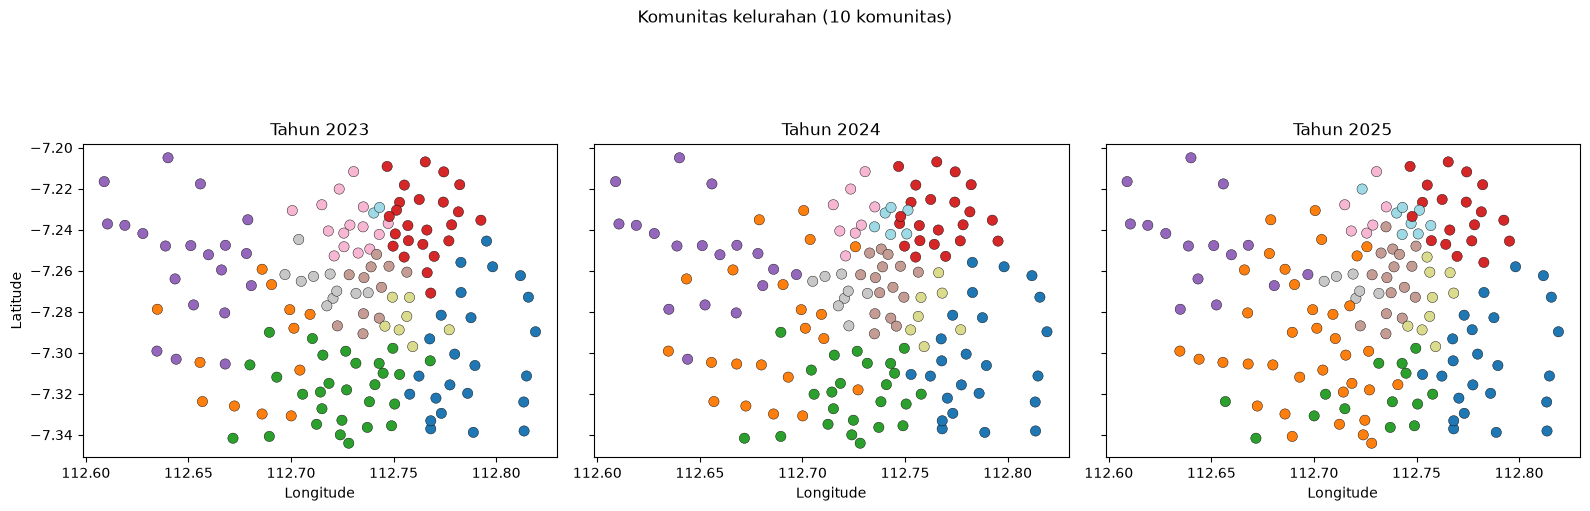

In [10]:
ncom = nodes["komunitas"].max(); cmap = plt.get_cmap("tab20", max(ncom, 1))
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)
for ax, t in zip(axes, sorted(nodes.tahun.unique())):
    g = nodes[nodes.tahun == t]
    ax.scatter(g.lon_kelurahan, g.lat_kelurahan, c=g.komunitas, cmap=cmap, vmin=0.5, vmax=ncom + 0.5, s=55, edgecolor="k", linewidth=0.3)
    ax.set_title(f"Tahun {t}"); ax.set_xlabel("Longitude"); ax.set_aspect("equal")
axes[0].set_ylabel("Latitude")
fig.suptitle(f"Komunitas kelurahan ({ncom} komunitas)", y=1.0)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "peta_komunitas.png", dpi=150); plt.show()

## 11. Uji sensitivitas



In [ ]:
keep = (nodes.n_pengaduan >= LOW_VOLUME_THRESHOLD).to_numpy()
runs = [run_louvain(W[np.ix_(keep, keep)], s) for s in SEEDS]
lab_k = runs[int(np.argmax([r[1] for r in runs]))][0]
print(f"Node dibuang: {int((~keep).sum())} | ARI komunitas (tersisa) vs komunitas penuh: {ARI(nodes.komunitas.to_numpy()[keep], lab_k):.3f}")

piv = nodes.pivot(index="lokasi_key", columns="tahun", values="komunitas")
real = (piv.nunique(axis=1) == 1).mean()
rng = np.random.default_rng(SEED); acak = []
for _ in range(200):
    sh = piv.copy()
    for c in sh.columns:
        sh[c] = rng.permutation(sh[c].to_numpy())
    acak.append((sh.nunique(axis=1) == 1).mean())
print(f"Kelurahan dengan komunitas sama di semua tahun: {real:.1%} | acak (200x): {np.mean(acak):.1%} ± {np.std(acak):.1%}")

Node dibuang: 6 | ARI komunitas (tersisa) vs komunitas penuh: 0.888
Kelurahan dengan komunitas sama di semua tahun: 62.1% | acak (200x): 1.5% ± 1.0%


## 12 Ablation terkontrol: pengaruh batas spasial dan temporal

Empat skenario yang dibandingkan:

- **Full (geo + time):** K-nearest kelurahan dan selisih tahun ≤ 1. Ini merepresentasikan desain utama.
- **Tanpa spasial (time only):** semua pasangan kelurahan yang memenuhi selisih tahun ≤ 1; tidak dibatasi K-nearest geografis.
- **Tanpa temporal (geo only):** K-nearest geografis tanpa pembatasan selisih tahun.
- **Tanpa spasial dan temporal (semantic global):** seluruh pasangan node dapat menjadi kandidat.

Pada setiap skenario, tiap node memilih hingga M tetangga dengan cosine positif tertinggi di antara kandidat yang diizinkan, kemudian edge disimetriskan. Karena himpunan kandidat berbeda, jumlah edge akhir memang dapat berbeda; ini bukan eksperimen dengan densitas graf yang dipaksa sama, melainkan *constraint ablation* yang mengisolasi pengaruh pembatas spasial dan temporal di bawah prosedur pembobotan/pemilihan tetangga yang sama.


In [ ]:
# Constraint ablation: hanya aturan kandidat yang diubah.
def _semantic_knn_from_allowed(allowed, similarity, m):
    """Pilih hingga M cosine positif tertinggi per node pada kandidat yang diizinkan."""
    allowed = np.asarray(allowed, dtype=bool).copy()
    np.fill_diagonal(allowed, False)
    sim_pos = np.clip(np.asarray(similarity, dtype=float), 0.0, None)
    selected = np.zeros_like(allowed, dtype=bool)

    for i in range(allowed.shape[0]):
        candidates = np.flatnonzero(allowed[i] & (sim_pos[i] > 0))
        if len(candidates) == 0:
            continue
        order = candidates[np.argsort(-sim_pos[i, candidates], kind="stable")]
        chosen = order[:int(m)]
        selected[i, chosen] = True

    selected = selected | selected.T
    W_out = np.where(selected, sim_pos, 0.0)
    return W_out

K_ab = int(cfg["k_geo"])
M_ab = int(cfg["m"])
scope_ab = str(cfg["scope"])

A_geo = geo_neighbors(K_ab)[np.ix_(ki, ki)].copy()
np.fill_diagonal(A_geo, True)
A_time = np.abs(yr[:, None] - yr[None, :]) <= 1
np.fill_diagonal(A_time, False)

# Skenario nested: full, drop spatial, drop temporal, drop both.
candidate_scenarios = [
    ("Full: geo + time", A_geo & A_time),
    ("Tanpa spasial: time only", A_time),
    ("Tanpa temporal: geo only", A_geo),
    ("Tanpa spasial & temporal: global", np.ones((N, N), dtype=bool)),
]

constraint_ablation_rows = []
constraint_ablation_labels = {}

for scenario_name, allowed_pairs in candidate_scenarios:
    allowed_pairs = np.asarray(allowed_pairs, dtype=bool).copy()
    np.fill_diagonal(allowed_pairs, False)

    W_ab = _semantic_knn_from_allowed(allowed_pairs, SIM, M_ab)
    if NORMALIZE_LAYERS and np.any(W_ab > 0):
        W_ab = W_ab / W_ab[W_ab > 0].mean()

    result, label = evaluate(W_ab, scenario_name)
    result["candidate_pairs"] = int(np.triu(allowed_pairs, 1).sum())
    result["k_geo"] = K_ab
    result["m_semantic"] = M_ab
    constraint_ablation_rows.append(result)
    constraint_ablation_labels[scenario_name] = label

constraint_ablation_results = pd.DataFrame(constraint_ablation_rows)
display(constraint_ablation_results.drop(columns=[], errors="ignore").round(3))

constraint_ablation_results.to_csv(
    OUTPUT_DIR / "constraint_ablation_results.csv",
    index=False, encoding="utf-8-sig"
)

constraint_ablation_design = {
    "ablation_type": "nested_candidate_constraint_ablation",
    "main_scope": scope_ab,
    "k_geo": K_ab,
    "m_semantic": M_ab,
    "weight": "positive IndoBERT cosine similarity",
    "selection": "up to M highest positive semantic similarities per node among allowed candidates",
    "symmetrization": "union of directed node selections",
    "scenarios": [
        "full_geo_and_time",
        "time_only_without_geo",
        "geo_only_without_time",
        "global_without_geo_or_time"
    ],
    "interpretation": (
        "Tests the effect of spatial/temporal candidate restrictions. "
        "It does not test geographic affinity as an additive edge-weight layer."
    )
}
with open(OUTPUT_DIR / "constraint_ablation_design.json", "w", encoding="utf-8") as f:
    json.dump(constraint_ablation_design, f, ensure_ascii=False, indent=2)

# Pemeriksaan bahwa skenario Full mereproduksi graf utama secara substantif.
W_main_check = np.asarray(W, dtype=float)
W_full_check = _semantic_knn_from_allowed(candidate_scenarios[0][1], SIM, M_ab)
if NORMALIZE_LAYERS and np.any(W_full_check > 0):
    W_full_check = W_full_check / W_full_check[W_full_check > 0].mean()

same_support = np.array_equal(W_main_check > 0, W_full_check > 0)
max_abs_diff = float(np.max(np.abs(W_main_check - W_full_check)))
print(f"Full ablation vs graf utama — support identik: {same_support}; "
      f"maksimum selisih bobot: {max_abs_diff:.8f}")
print("Desain dan hasil tersimpan di:", OUTPUT_DIR)


,name,Q,n_comm,min_size,max_size,ARI_seed,sem_gain,topic_gain,spat_ratio,cross_year,n_edges,candidate_pairs,k_geo,m_semantic
0,Full: geo + time,0.734,10,16,72,0.806,0.126,0.151,0.506,1.0,1984,8034,12,6
1,Tanpa spasial: time only,0.566,7,32,118,0.587,0.239,0.204,0.953,1.0,2324,81702,12,6
2,Tanpa temporal: geo only,0.746,11,12,77,0.749,0.129,0.139,0.469,1.0,2011,10395,12,6
3,Tanpa spasial & temporal: global,0.582,7,29,100,0.713,0.237,0.198,0.964,1.0,2326,105111,12,6


Full ablation vs graf utama — support identik: True; maksimum selisih bobot: 0.00000012
Desain dan hasil tersimpan di: c:\Users\DELL\Downloads\Bismillah skripsi lancar jaya nilai A\semantic_output


## 13. Perbandingan Louvain dan Leiden pada graf utama yang sama



In [ ]:
# Louvain vs Leiden pada graf utama W yang sama
def _leiden_partition_networkx(W, seed):
    Gx = nx.from_numpy_array(W)
    parts = nx.community.leiden_communities(
        Gx, weight="weight", resolution=1.0, seed=int(seed)
    )
    labels = np.zeros(len(W), dtype=int)
    for cid, members in enumerate(parts):
        for node_id in members:
            labels[int(node_id)] = cid
    q = nx.community.modularity(Gx, parts, weight="weight")
    return labels, float(q)

def _leiden_partition_igraph(W, seed):
    try:
        import igraph as ig
        import leidenalg
    except ImportError as exc:
        raise ImportError(
            "Leiden belum tersedia. Perbarui NetworkX (yang menyediakan "
            "nx.community.leiden_communities) atau instal `igraph` dan `leidenalg`."
        ) from exc

    ii, jj = np.where(np.triu(W, 1) > 0)
    graph = ig.Graph(n=W.shape[0], edges=list(zip(ii.tolist(), jj.tolist())), directed=False)
    graph.es["weight"] = W[ii, jj].astype(float).tolist()
    part = leidenalg.find_partition(
        graph,
        leidenalg.RBConfigurationVertexPartition,
        weights="weight",
        resolution_parameter=1.0,
        seed=int(seed)
    )
    labels = np.asarray(part.membership, dtype=int)

    Gx = nx.from_numpy_array(W)
    groups = [set(np.where(labels == c)[0].tolist()) for c in np.unique(labels)]
    q = nx.community.modularity(Gx, groups, weight="weight")
    return labels, float(q)

def run_leiden(W, seed):
    if not (W > 0).any():
        raise ValueError("Graf utama tidak memiliki edge positif.")
    if hasattr(nx.community, "leiden_communities"):
        try:
            return _leiden_partition_networkx(W, seed)
        except NotImplementedError:
            print(
                "NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; "
                "beralih ke igraph + leidenalg."
            )
        except (ImportError, ModuleNotFoundError):
            print("Backend NetworkX Leiden tidak tersedia; beralih ke igraph + leidenalg.")

    return _leiden_partition_igraph(W, seed)

# Hasil Louvain menggunakan fungsi dan seed yang sama seperti evaluasi utama
louvain_runs = [run_louvain(W, s) for s in SEEDS]
leiden_runs = [run_leiden(W, s) for s in SEEDS]

def _algorithm_summary(name, runs):
    labs = [r[0] for r in runs]
    qs = [r[1] for r in runs]
    pair_ari = [ARI(labs[i], labs[j])
                for i in range(len(labs)) for j in range(i + 1, len(labs))]
    best_idx = int(np.argmax(qs))
    best_lab = labs[best_idx]
    sizes = np.bincount(best_lab)
    return {
        "algoritma": name,
        "Q_tertinggi": float(np.max(qs)),
        "Q_rata_rata": float(np.mean(qs)),
        "Q_std": float(np.std(qs, ddof=1)) if len(qs) > 1 else 0.0,
        "jumlah_komunitas": int(len(sizes)),
        "ukuran_min": int(sizes.min()),
        "ukuran_maks": int(sizes.max()),
        "ARI_antar_seed_rata2": float(np.mean(pair_ari)) if pair_ari else np.nan,
        "label_seed_Q_tertinggi": best_lab
    }

sum_louvain = _algorithm_summary("Louvain", louvain_runs)
sum_leiden = _algorithm_summary("Leiden", leiden_runs)

algorithm_comparison = pd.DataFrame([
    {k: v for k, v in sum_louvain.items() if k != "label_seed_Q_tertinggi"},
    {k: v for k, v in sum_leiden.items() if k != "label_seed_Q_tertinggi"}
])
display(algorithm_comparison.round(3))
algorithm_comparison.to_csv(OUTPUT_DIR / "louvain_vs_leiden_summary.csv", index=False, encoding="utf-8-sig")

# Bandingkan partisi seed dengan modularity tertinggi antar algoritma
ari_louvain_leiden = ARI(
    sum_louvain["label_seed_Q_tertinggi"],
    sum_leiden["label_seed_Q_tertinggi"]
)
print(f"ARI partisi Louvain vs Leiden (masing-masing seed dengan Q tertinggi): {ari_louvain_leiden:.3f}")

# Simpan keanggotaan pembanding tanpa mengubah membership utama Louvain
nodes_leiden = nodes.copy()
nodes_leiden["komunitas_leiden"] = sum_leiden["label_seed_Q_tertinggi"] + 1
nodes_leiden.to_csv(OUTPUT_DIR / "community_membership_leiden_comparison.csv",
                    index=False, encoding="utf-8-sig")


NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.
NetworkX Leiden API tersedia tetapi backend belum diimplementasikan; beralih ke igraph + leidenalg.


,algoritma,Q_tertinggi,Q_rata_rata,Q_std,jumlah_komunitas,ukuran_min,ukuran_maks,ARI_antar_seed_rata2
0,Louvain,0.734,0.731,0.002,10,16,72,0.806
1,Leiden,0.736,0.735,0.001,9,20,76,0.870


ARI partisi Louvain vs Leiden (masing-masing seed dengan Q tertinggi): 0.789


## 14. Uji sensitivitas jumlah tetangga geografis (Kgeo)



In [ ]:
# Sensitivitas Kgeo: M, scope, embedding, dan seed dipertahankan
K_GEO_SENSITIVITY = [8, 12, 16]
M_fixed = int(cfg["m"])
scope_fixed = str(cfg["scope"])
main_labels = np.asarray(nodes["komunitas"], dtype=int)

kgeo_runs = {}
kgeo_rows = []

for K_test in K_GEO_SENSITIVITY:
    W_test = build_geo_semantic(scope_fixed, int(K_test), M_fixed)
    result_test, labels_test = evaluate(
        W_test, f"sensitivitas Kgeo={K_test}"
    )
    labels_test = np.asarray(labels_test, dtype=int)
    kgeo_runs[int(K_test)] = {
        "W": W_test,
        "labels": labels_test,
        "result": result_test
    }

    row = dict(result_test)
    row.update({
        "scope": scope_fixed,
        "k_geo": int(K_test),
        "m_semantic": M_fixed,
        "n_candidate_edges": int(np.triu(W_test > 0, 1).sum()),
        "ARI_vs_main_K12": float(ARI(main_labels, labels_test))
    })
    kgeo_rows.append(row)

kgeo_sensitivity = pd.DataFrame(kgeo_rows)

W_k12 = kgeo_runs[12]["W"]
support_identical_k12 = np.array_equal(W > 0, W_k12 > 0)
max_weight_diff_k12 = float(np.max(np.abs(W - W_k12)))

print("Konfigurasi tetap:", {"scope": scope_fixed, "M": M_fixed})
print("Graf Kgeo=12 identik dengan graf utama (support):", support_identical_k12)
print("Selisih bobot maksimum Kgeo=12 vs graf utama:", f"{max_weight_diff_k12:.10g}")
display(kgeo_sensitivity.round(3))

kgeo_sensitivity.to_csv(
    OUTPUT_DIR / "kgeo_sensitivity_results.csv",
    index=False, encoding="utf-8-sig"
)

kgeo_design = {
    "experiment": "geographic_neighbor_count_sensitivity",
    "tested_k_geo": K_GEO_SENSITIVITY,
    "fixed_m_semantic": M_fixed,
    "fixed_scope": scope_fixed,
    "fixed_embedding_representation": "mean_centered",
    "algorithm": "Louvain",
    "seeds": [int(s) for s in SEEDS],
    "comparison_partition": "main Louvain partition at Kgeo=12",
    "metrics": [
        "Q", "n_comm", "min_size", "max_size", "ARI_seed",
        "sem_gain", "topic_gain", "spat_ratio", "cross_year",
        "n_candidate_edges", "ARI_vs_main_K12"
    ],
    "k12_graph_support_identical_to_main": bool(support_identical_k12),
    "k12_max_absolute_weight_difference": max_weight_diff_k12,
    "interpretation": (
        "Only Kgeo changes. Select based on a multi-criteria assessment; "
        "modularity alone is insufficient. ARI_vs_main_K12 is agreement "
        "with the current main partition, not external ground truth."
    )
}
with open(OUTPUT_DIR / "kgeo_sensitivity_design.json", "w", encoding="utf-8") as f:
    json.dump(kgeo_design, f, ensure_ascii=False, indent=2)

print("Tersimpan: kgeo_sensitivity_results.csv dan kgeo_sensitivity_design.json")


Konfigurasi tetap: {'scope': 'spatio_temporal_consecutive', 'M': 6}
Graf Kgeo=12 identik dengan graf utama (support): True
Selisih bobot maksimum Kgeo=12 vs graf utama: 0


,name,Q,n_comm,min_size,max_size,ARI_seed,sem_gain,topic_gain,spat_ratio,cross_year,n_edges,scope,k_geo,m_semantic,n_candidate_edges,ARI_vs_main_K12
0,sensitivitas Kgeo=8,0.771,10,19,92,0.742,0.089,0.105,0.487,1.0,1889,spatio_temporal_consecutive,8,6,1889,0.711
1,sensitivitas Kgeo=12,0.734,10,16,72,0.806,0.126,0.151,0.506,1.0,1984,spatio_temporal_consecutive,12,6,1984,1.000
2,sensitivitas Kgeo=16,0.708,10,18,73,0.656,0.161,0.157,0.497,1.0,2031,spatio_temporal_consecutive,16,6,2031,0.576


Tersimpan: kgeo_sensitivity_results.csv dan kgeo_sensitivity_design.json
